In [2]:
import os

corpus = [] #initial empty list

os.getcwd() #get current path

data_folder = os.path.join(os.getcwd(), "korpus") #join current path with directory name
print(list(os.walk(data_folder))) #check files inside of chosen directory

for root, folders, files in os.walk(data_folder): #structure of list is root -> folders -> files
    for file in files:
        path = os.path.join(root, file)
        with open(path, encoding="utf8") as input: #encode in utf8 for special characters like ä.ü,ö,ß
            corpus.append(input.read()) #append every file as new list-item
input.close()

print(len(corpus),"Texte wurden erfolgreich in den Korpus geladen.")

[('c:\\workspace\\nlp-lernen\\korpus', [], ['achleitner-Aus_Kroatien.txt', 'achleitner-Bergrichters_Erdenwallen.txt', 'achleitner-Celsissimus.txt', 'achleitner-Im_gruenen_Tann.txt', 'achleitner-Unter_den_Hohen_Tauern.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 01.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 40.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 42.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 56.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 63.txt', 'anonymous-Der Luftpirat und sein lenkbares Luftschiff 66.txt', 'goethe-die_leiden_des_jungen_werther_band1.txt', 'goethe-die_leiden_des_jungen_werther_band2.txt', 'goethe-faust1.txt', 'goethe-faust2.txt', 'goethe-wahlverwandtschaften.txt', 'goethe-wilhelm_meisters_lehrjahre_band1.txt', 'goethe-wilhelm_meisters_wanderjahre_band1.txt', 'kafka-betrachtung.txt', 'kafka-das_urteil.txt', 'kafka-der_prozess.txt', 'kafka-die_verwandlung.txt', 'kafka-hungerküns

In [4]:
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re

corpus_list = []
#corpus_vec = []
corpus_name = []

def number_words(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    return len(text_words)

def avg_word_len(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    avg_word_len = sum(len(word) for word in text_words) / len(text_words)
    return round(avg_word_len,1)

def number_sentences(text):
    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    return len(sentences)

def avg_sen_len(text):
    avg_sen_len = round(number_words(text) / number_sentences(text),1) #average sentence length
    return avg_sen_len

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def syllables_count(text, sprache='de_DE'):
    dic = pyphen.Pyphen(lang=sprache)
    worte = text.split()
    #print(worte)
    silben_gesamt = 0
    global syll1
    syll1 = 0
    
    for wort in worte:
        silben = dic.inserted(wort).split('-')
        #print(silben, len(silben))
        if len(silben) == 1:
            syll1 += 1
            #print("Silbe hier:",len(silben),"---->",silben)
        silben_gesamt += len(silben)

    return silben_gesamt

def avg_syllables_per_word(var3):
    #print("Übermittel var3:",var3)
    words = re.findall(r'\b\w+\b', var3.lower())
    avg_syllables = syllables_count(var3) / len(words)
    #print("Silben:",syllables_count(var3))
    #print("Wörter:",len(words))
    return round(avg_syllables, 1)

def flesch_reading_ease_ger(asl, asw):
    
    fre = 180 - asl - (58.5 - asw)
    
    return round(fre,2)

def wiener_sachtext_formel(text):
    syll = 0
    ms = 0 
    sl = 0
    iw = 0
    es = 0
    words6 = 0
    global syll1

    if syllables_count(text) > 3:
        syll += 1
    ms = syll / number_words(text) * 100
    sl = avg_sen_len(text)

    words = re.findall(r'\b\w+\b', text.lower())
    for word in words:
        if len(word) > 5:
            #print("hier:",len(word),"---->",word)
            words6 += 1
    iw = words6 / number_words(text)
    es = syll1 / number_words(text) * 100
    # print("MS:",ms)
    # print("SL:",sl)
    # print("SL:",sl)
    # print("IW:",iw)
    # print("ES:",es)

    # print("syll1:",syll1)
    # print("# Words:",number_words(text))
    #print("Formel: 0.1935 *", ms,"+ 0.1672 *", sl,"+ 0.1297 *", iw,"- 0.0327 *", es," - 0.875")

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf,2)

def ngram_haeufigkeit(text):
    # Kleinbuchstaben & Tokenisierung
    tokens = word_tokenize(text.lower())

    # Bigramme & Trigramme erzeugen
    bigramme = list(ngrams(tokens, 2))
    trigramme = list(ngrams(tokens, 3))

    # Häufigkeiten zählen
    bigram_haeufigkeit = Counter(bigramme)
    trigram_haeufigkeit = Counter(trigramme)

    # Ergebnisse anzeigen
    print(f"Anzahl eindeutiger Bigramme: {len(bigram_haeufigkeit)}")
    print(f"Anzahl eindeutiger Trigramme: {len(trigram_haeufigkeit)}\n")

    print("Top 5 Bigramme:")
    for bigram, count in bigram_haeufigkeit.most_common(5):
        print(f"{bigram} → {count} Mal")

    print("\nTop 5 Trigramme:")
    for trigram, count in trigram_haeufigkeit.most_common(5):
        print(f"{trigram} → {count} Mal")



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\textstat\textstat.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [5]:
for text in corpus:

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #nltk_text_words = word_tokenize(text)
    
    wordcount = number_words(text)
    sentencescount = number_sentences(text)
    print(wordcount,sentencescount)

    avgsenlen = avg_sen_len(text) #average sentence length
    #print(avg_sen_len)
    avgwordlen = avg_word_len(text)
    #print(avg_word_len)
    #print(avgwordlen,avgsenlen)


    ttr_erg = round(ttr(nltk_text),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text)
    fre_ger = flesch_reading_ease_ger(avgsenlen, avg_syll)
    wsf = wiener_sachtext_formel(text)
    print(avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg)
    print(ngram_haeufigkeit(text))

    corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    #corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg])
    corpus_name.append(nltk_text)

    print("-----------------------------------------------")

#print("Corpuslist:",corpus_list)

33281 1853
5.8 18.0 1.9 0.63 0.22
Anzahl eindeutiger Bigramme: 28450
Anzahl eindeutiger Trigramme: 38070

Top 5 Bigramme:
(',', 'daß') → 218 Mal
('!', '“') → 199 Mal
(',', 'die') → 150 Mal
(',', 'der') → 125 Mal
('.', 'der') → 121 Mal

Top 5 Trigramme:
('!', '“', '„') → 65 Mal
(',', 'daß', 'der') → 46 Mal
('?', '“', '„') → 32 Mal
(',', 'daß', 'die') → 26 Mal
(',', 'daß', 'er') → 13 Mal
None
-----------------------------------------------
46250 2530
5.5 18.3 1.8 0.56 0.17
Anzahl eindeutiger Bigramme: 35653
Anzahl eindeutiger Trigramme: 50585

Top 5 Bigramme:
('!', '“') → 592 Mal
('“', '„') → 586 Mal
('.', '„') → 301 Mal
('?', '“') → 285 Mal
(',', 'daß') → 259 Mal

Top 5 Trigramme:
('!', '“', '„') → 309 Mal
('?', '“', '„') → 207 Mal
('“', '„', 'ich') → 44 Mal
(',', 'daß', 'der') → 38 Mal
('“', '„', 'ja') → 35 Mal
None
-----------------------------------------------
68271 2948
5.5 23.2 1.8 1.43 0.16
Anzahl eindeutiger Bigramme: 50872
Anzahl eindeutiger Trigramme: 73676

Top 5 Bigramme:
('

# Support Vector Machine

In [6]:
# Load the important packages
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn import svm
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report
import sklearn.metrics as metrics

colu = ['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables', 'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .', 'Avg ,', 'Avg ;', 'Avg :']
corp = pd.DataFrame(corpus_list)
corp.columns = colu
corp["Author"]= ["Achleitner", "Achleitner", "Achleitner", "Achleitner", "Achleitner", "Anonymous", "Anonymous", "Anonymous", "Anonymous", "Anonymous", "Anonymous", "Goethe", "Goethe", "Goethe", "Goethe", "Goethe", "Goethe", "Goethe", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Kafka", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller", "Schiller"]

corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,5.8,18.0,1.9,0.63,105.4,0.22,0.013,0.003,0.036,0.061,0.005,0.003,Achleitner
1,5.5,18.3,1.8,0.56,105.0,0.17,0.022,0.007,0.032,0.062,0.001,0.002,Achleitner
2,5.5,23.2,1.8,1.43,100.1,0.16,0.018,0.004,0.024,0.071,0.002,0.004,Achleitner
3,5.3,19.8,1.7,0.72,103.4,0.17,0.017,0.004,0.030,0.066,0.004,0.004,Achleitner
4,5.5,15.7,1.8,0.18,107.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005,Achleitner
5,5.4,18.9,1.8,0.69,104.4,0.21,0.004,0.002,0.042,0.088,0.000,0.000,Anonymous
6,5.4,15.8,1.8,0.16,107.5,0.20,0.001,0.003,0.051,0.073,0.000,0.000,Anonymous
7,5.4,16.6,1.8,0.32,106.7,0.20,0.001,0.002,0.049,0.074,0.000,0.000,Anonymous
8,5.4,16.6,1.8,0.32,106.7,0.21,0.001,0.001,0.051,0.072,0.000,0.000,Anonymous
9,5.5,15.3,1.8,0.10,108.0,0.21,0.001,0.001,0.054,0.073,0.000,0.000,Anonymous


In [7]:
X = corp[colu] # Features
y = corp.Author # Target variable

In [8]:
X2 = X.drop(X.columns[2:], axis=1)
y2 = corp.iloc[:,12]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X2, y2, random_state=33, test_size=0.2)

clf = svm.SVC(kernel="linear", gamma=1000, C=1000)
clf_fit = clf.fit(X_train, y_train)
clf_fit.score(X_train, y_train)

0.8

In [10]:
color_map = {
    1: '#FF0000',   # red
    2: '#0000FF',   # blue
    3: '#008000',   # green
    4: '#FFA500',   # orange
    5: '#800080',   # purple
    6: '#FFFF00',   # yellow
    7: '#FF00FF',   # black
    8: '#000000',   # lime green
    9: '#A2C523',   # magenta
    10: "#48C5FF"   # sky blue
}

df_y2 = pd.DataFrame(y2)
werte = [2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 4, 1, 1, 1, 1, 1, 1, 1, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
df_y2["Color"] = werte
df_y2['ColorName'] = df_y2['Color'].map(color_map)

from matplotlib.lines import Line2D
custom_legend = [
    Line2D([0], [0], marker='o', color='b', label='Achleitner', markerfacecolor='#0000FF', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Anonymous', markerfacecolor='#FFA500', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Goethe', markerfacecolor='#FF0000', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Kafka', markerfacecolor='#FF00FF', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Schiller', markerfacecolor='#008000', markersize=10)
]

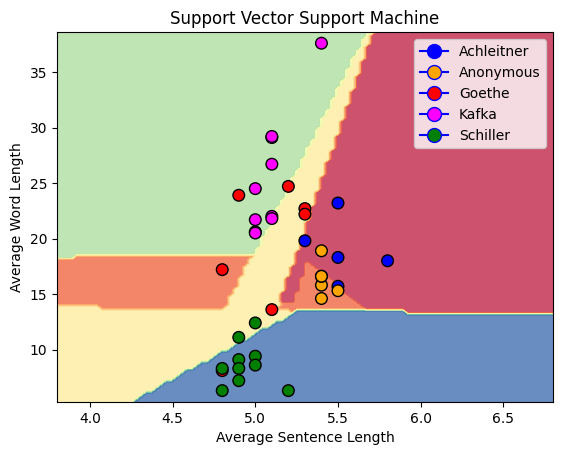

In [11]:
# Plot Decision Boundary
DecisionBoundaryDisplay.from_estimator(
        clf_fit,
        X2,
        response_method="predict",
        cmap=plt.cm.Spectral,
        alpha=0.8,
        xlabel=X2.columns[0],
        ylabel=X2.columns[1],
    )

# Scatter plot
#plt.figure(figsize=(10,26))
plt.title('Support Vector Support Machine')
plt.scatter(X2.iloc[:, 0], X2.iloc[:, 1], 
            c=df_y2['ColorName'], 
            s=70, edgecolors="k")
plt.legend(handles=custom_legend)
plt.xlabel("Average Sentence Length")
plt.ylabel("Average Word Length")
#plt.colorbar()
plt.show()

In [12]:
y_pred = clf_fit.predict(X_test)

In [13]:
accuracy = metrics.accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 75.00%


In [14]:

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       0.00      0.00      0.00         0
   Anonymous       0.00      0.00      0.00         1
      Goethe       0.00      0.00      0.00         0
       Kafka       1.00      1.00      1.00         2
    Schiller       1.00      0.80      0.89         5

    accuracy                           0.75         8
   macro avg       0.40      0.36      0.38         8
weighted avg       0.88      0.75      0.81         8



c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-lernen\nlp-lernen\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\workspace\nlp-l

### 10 Fold Cross Valdidation

In [15]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf_fit, X2, y2, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("\nAverage CV Score: ", scores.mean())
print("\nNumber of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.5        0.5        0.75       0.25       0.5        1.
 0.75       1.         0.66666667 0.66666667]

Average CV Score:  0.6583333333333334

Number of CV Scores used in Average:  10


## Confusion Matrix

In [16]:
confusion_matrix(y_test, y_pred)

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0],
       [0, 0, 0, 2, 0],
       [0, 0, 1, 0, 4]])

In [17]:
df_cm = pd.DataFrame()
df_cm["True"] = y_test
df_cm["Predict"] = y_pred
df_cm

,True,Predict
28,Schiller,Schiller
22,Kafka,Kafka
34,Schiller,Goethe
33,Schiller,Schiller
5,Anonymous,Achleitner
32,Schiller,Schiller
23,Kafka,Kafka
37,Schiller,Schiller


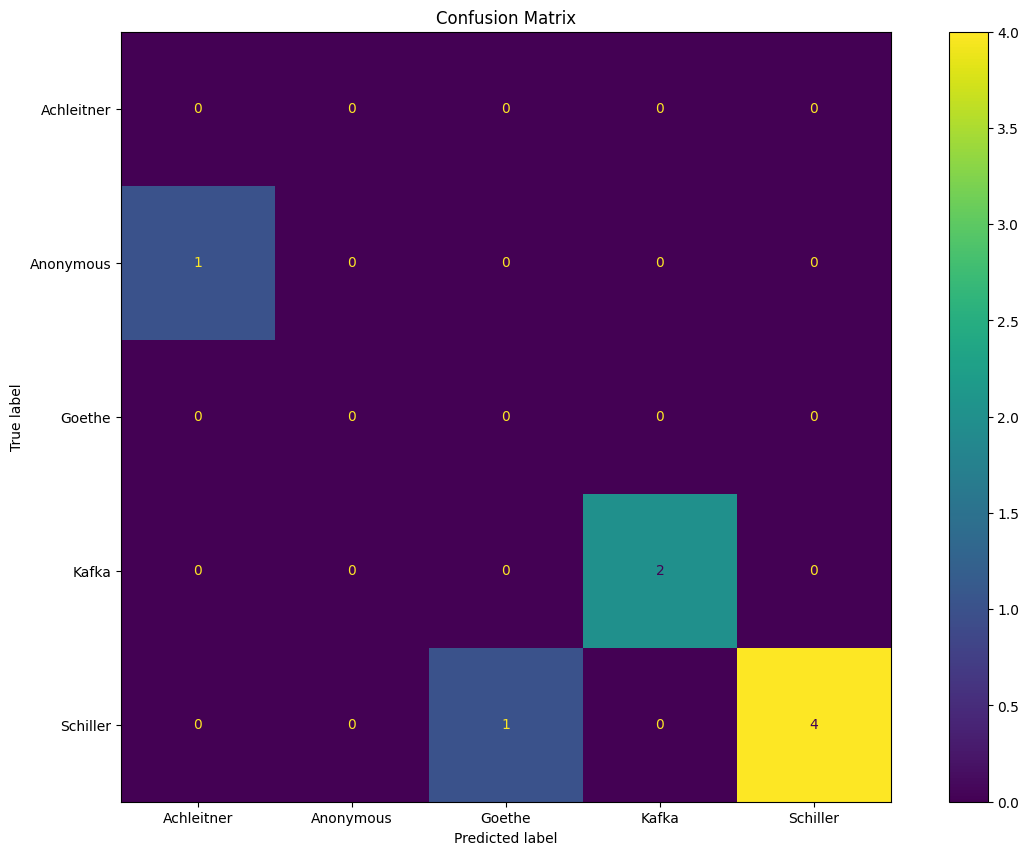

In [18]:
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ['Achleitner', 'Anonymous', 'Goethe', 'Kafka', 'Schiller']) #Reihenefolge?

disp = cm_display.plot()
disp.figure_.set_size_inches(15, 10)
plt.title("Confusion Matrix")
plt.show()

### Grid Search

In [2]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Datensatz laden und aufteilen
data = load_iris()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42)

# Pipeline mit Standard-Skalierung und SVM
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])

# Zu optimierende Hyperparameter im Grid definieren
param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__kernel': ['linear', 'rbf', 'poly'],
    'svm__gamma': ['scale', 'auto']  # relevant für 'rbf' und 'poly'
}

# GridSearchCV-Objekt mit 5-fach Cross-Validation
grid_search = GridSearchCV(pipe,
                           param_grid=param_grid,
                           cv=5,
                           scoring='accuracy',
                           n_jobs=-1)  # nutzt alle CPUs

# Grid-Search durchführen
grid_search.fit(X_train, y_train)

# Beste Kombination und Performance ausgeben
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy: {:.3f}".format(grid_search.best_score_))

# Bestes Modell auf äußerem Testdatensatz evaluieren
best_model = grid_search.best_estimator_
test_accuracy = best_model.score(X_test, y_test)
print("Test set accuracy: {:.3f}".format(test_accuracy))


Best parameters: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best cross-validation accuracy: 0.958
Test set accuracy: 1.000


### Standardabweichung 10-Fold-CV

CV scores per fold:  [1.     1.     1.     0.9333 0.8667 0.9333 1.     1.     0.9333 0.9333]
Mean score: 0.9600
Standard deviation (SD): 0.0442
Standard error (SE): 0.0140  (SD/sqrt(K))
Bootstrap 200 iter. 95% CI for mean: [0.9333, 0.9933]
(Bootstrap runtime: 5.7s)


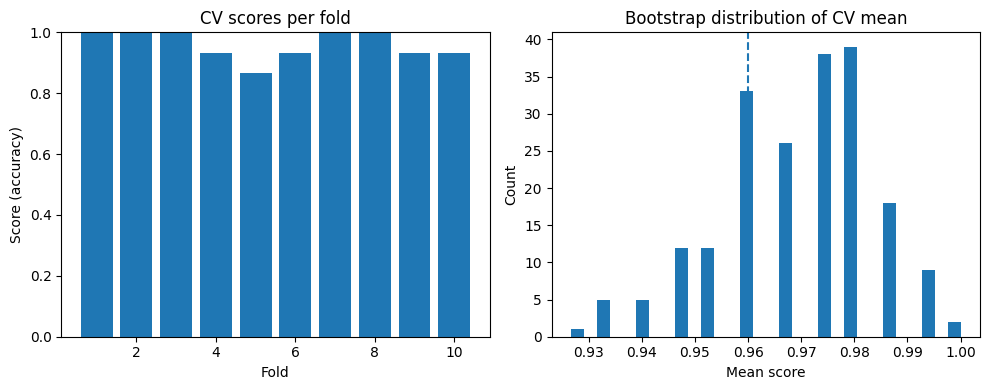

{'mean': np.float64(0.96),
 'sd': np.float64(0.04422166387140532),
 'se': np.float64(0.013984117975602015),
 'ci_lower': np.float64(0.9333333333333333),
 'ci_upper': np.float64(0.9933333333333334),
 'scores': array([1.        , 1.        , 1.        , 0.93333333, 0.86666667,
        0.93333333, 1.        , 1.        , 0.93333333, 0.93333333])}

: 

In [ ]:
# Demo: 10-Fold Cross-Validation mit SVM — Mean, SD, SE und Bootstrap-CI
# Diese Zelle führt eine 10-fach CV durch, berechnet Mean, Std (SD), Std Error (SE)
# und ein 95%-Konfidenzintervall des Mittelwerts via Bootstrap.
#
# Du kannst die Funktion `evaluate_cv` auf deine eigenen X,y und ein beliebiges sklearn-Modell
# anwenden (z. B. ein Pipeline-Objekt mit Scaling + SVC).

from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
import numpy as np
import matplotlib.pyplot as plt
import time

def evaluate_cv(model, X, y, cv=10, scoring='accuracy', n_jobs=1, random_state=42,
                bootstrap_iters=1000, bootstrap_seed=42, verbose=True):
    """
    Führt eine K-fold CV aus und berechnet:
      - scores per fold (array)
      - mean score
      - standard deviation (SD) of fold scores
      - standard error (SE) of the mean = SD / sqrt(K)
      - bootstrap confidence interval (percentile) for the mean score
      
    Parameters
    ----------
    model : sklearn estimator
    X, y  : data arrays
    cv : int (number of folds)
    scoring : scoring string for cross_val_score
    n_jobs : jobs for cross_val_score
    bootstrap_iters : number of bootstrap resamples for CI (default 1000)
    
    Returns
    -------
    dict containing scores, mean, sd, se, ci_lower, ci_upper, bootstrap_means
    """
    rng = np.random.RandomState(random_state)
    if isinstance(cv, int):
        cv_splitter = StratifiedKFold(n_splits=cv, shuffle=True, random_state=random_state)
    else:
        cv_splitter = cv  # allow user-supplied splitter
    
    # 1) K-fold CV
    scores = cross_val_score(model, X, y, cv=cv_splitter, scoring=scoring, n_jobs=n_jobs)
    mean_score = scores.mean()
    sd_score = scores.std()   # population std (ddof=0) — standard practice for CV reporting
    se_score = sd_score / np.sqrt(len(scores))
    
    # 2) Bootstrap CI for the mean score (bootstrap over the dataset)
    #    For each bootstrap iteration: draw indices with replacement, compute CV mean on that sample.
    #    This is computationally heavier but gives an empirical CI for the mean performance.
    B = int(bootstrap_iters)
    bootstrap_means = np.empty(B)
    n_samples = X.shape[0]
    start = time.time()
    for b in range(B):
        idx = rng.randint(0, n_samples, size=n_samples)  # sample with replacement
        Xb = X[idx]
        yb = y[idx]
        try:
            sc = cross_val_score(model, Xb, yb, cv=cv_splitter, scoring=scoring, n_jobs=1)
            bootstrap_means[b] = sc.mean()
        except Exception as e:
            # falls ein Bootstrap-Resample problematisch ist (z.B. nur eine Klasse vorhanden),
            # setzen wir den Wert auf NaN und filtern später.
            bootstrap_means[b] = np.nan
    
    # drop NaNs if any (caused by degenerate bootstrap samples)
    bootstrap_means = bootstrap_means[~np.isnan(bootstrap_means)]
    ci_lower = np.percentile(bootstrap_means, 2.5)
    ci_upper = np.percentile(bootstrap_means, 97.5)
    elapsed = time.time() - start
    
    result = {
        'scores': scores,
        'mean': mean_score,
        'sd': sd_score,
        'se': se_score,
        'bootstrap_means': bootstrap_means,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper,
        'bootstrap_iters_used': len(bootstrap_means),
        'bootstrap_time_s': elapsed
    }
    
    if verbose:
        print("CV scores per fold: ", np.round(scores, 4))
        print(f"Mean score: {mean_score:.4f}")
        print(f"Standard deviation (SD): {sd_score:.4f}")
        print(f"Standard error (SE): {se_score:.4f}  (SD/sqrt(K))")
        print(f"Bootstrap {len(bootstrap_means)} iter. 95% CI for mean: [{ci_lower:.4f}, {ci_upper:.4f}]")
        print(f"(Bootstrap runtime: {elapsed:.1f}s)")
    
    # small plot of fold scores + bootstrap distribution
    fig, axs = plt.subplots(1,2, figsize=(10,4))
    axs[0].bar(range(1, len(scores)+1), scores)
    axs[0].set_xlabel("Fold")
    axs[0].set_ylabel(f"Score ({scoring})")
    axs[0].set_title("CV scores per fold")
    axs[0].set_ylim(0,1)
    
    axs[1].hist(bootstrap_means, bins=30)
    axs[1].axvline(mean_score, linestyle='--')
    axs[1].set_title("Bootstrap distribution of CV mean")
    axs[1].set_xlabel("Mean score")
    axs[1].set_ylabel("Count")
    plt.tight_layout()
    plt.show()
    
    return result

# Demo mit Iris-Datensatz und SVM-Pipeline
data = load_iris()
X = data.data
y = data.target

pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf', C=1, gamma='scale'))])

res = evaluate_cv(pipe, X, y, cv=10, scoring='accuracy', n_jobs=-1, bootstrap_iters=200, verbose=True)

res_summary = {
    'mean': res['mean'],
    'sd': res['sd'],
    'se': res['se'],
    'ci_lower': res['ci_lower'],
    'ci_upper': res['ci_upper'],
    'scores': res['scores']
}

res_summary

